In [93]:
# upload the required libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.preprocessing import PowerTransformer, QuantileTransformer, KBinsDiscretizer
from sklearn.preprocessing import FunctionTransformer

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer


from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression

In [94]:
# import the data

df = pd.read_csv('property_data.csv')
df.head()

,Unnamed: 0,Property_id,property_type,offer,governorate,bedrooms,bathrooms,rent,location,city,...,is_super_agent,broker_id,floor_plans,is_featured,is_premium,description,is_verified,is_verified.1,is_exclusive,is_exclusive.1
0,27387,7343b863-a2cb-4d85-b2dd-935ea61365ff,Apartment,Residential for Rent,"Capital Governorate, Manama",studio,1,245.0,NaN,NaN,...,True,1031.0,NaN,False,False,A different furnished studio opportunity in Sa...,False,False,False,False
1,18554,f1a36ab5-1601-4127-a7a7-5095f167acca,Apartment,Rent,Capital Governorate,1,1,300.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,9295,bf629ae9-a3b2-4c2e-8e0e-b0ffce916fa7,Compound,Rent,Northern Governorate,5,5,1200.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,28118,26707746-825c-4d65-b63c-dfaa69421365,Apartment,Residential for Rent,Capital Governorate,3,3,600.0,NaN,NaN,...,False,15.0,NaN,True,False,Spacious 3 Bedroom Apartment for Rent in Seef ...,False,False,False,False
4,689,dbc18ce8-1481-480c-9b66-a42653038408,Apartment,for rent,Muharraq Governorate,1,2,450.0,Al Marsa Floating City,Amwaj Islands,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## EDA 

In [95]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32090 entries, 0 to 32089
Data columns (total 41 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         32090 non-null  int64  
 1   Property_id        32090 non-null  str    
 2   property_type      32090 non-null  str    
 3   offer              32090 non-null  str    
 4   governorate        32090 non-null  str    
 5   bedrooms           32078 non-null  str    
 6   bathrooms          32086 non-null  str    
 7   rent               32090 non-null  float64
 8   location           2899 non-null   str    
 9   city               8206 non-null   str    
 10  area_sqm           32090 non-null  str    
 11  listing_date       22564 non-null  str    
 12  Property_id.1      32090 non-null  str    
 13  URL                23884 non-null  str    
 14  include_w_e        23884 non-null  str    
 15  title              23884 non-null  str    
 16  area               23884 non-null

In [96]:
cat_ohe = df.select_dtypes(include='object').columns.tolist()

for i in cat_ohe:
    print(f'no. of unique cats in {i} column:', df[i].nunique())
    print('unique cats', df[i].unique())
#df[['property_type', 'governorate', 'location', 'city', amenities]]

no. of unique cats in Property_id column: 32090
unique cats <ArrowStringArray>
['7343b863-a2cb-4d85-b2dd-935ea61365ff',
 'f1a36ab5-1601-4127-a7a7-5095f167acca',
 'bf629ae9-a3b2-4c2e-8e0e-b0ffce916fa7',
 '26707746-825c-4d65-b63c-dfaa69421365',
 'dbc18ce8-1481-480c-9b66-a42653038408',
 '4573ed83-c6a3-4fd8-8c48-2d85bf4042d0',
 '7048fd82-1af7-4556-bd84-39bab8283061',
 '02463af5-1ab9-4537-95e3-9bf6d820445b',
 '8e137aa1-0967-43ba-a584-b6faeb9d9a31',
 '084eaf42-83dd-4dbd-89ba-20b6244eeb68',
 ...
 '7d5758d0-4ccc-4f8c-81d4-d7dbc890c8a5',
 '0fe8bd75-7d16-47b2-8aed-91a53ac26af9',
 'bfbefe3f-4fd9-48dd-b3de-e6a0961b4ef0',
 '9f961339-2011-4413-86a3-ff0632aae4e5',
 '388a76e6-caf7-403f-ad02-ba4ed71b90de',
 '47c38a43-30f2-4541-8654-4cb28e85a2f2',
 '76705631-8076-4361-98e0-0f4aaaa6d67c',
 '515eeadb-ca7e-4a47-86ab-57bddab46bbe',
 '04a6a268-843e-49fb-b0bc-633f4a016d61',
 'ce78c0b9-9762-43fa-9d00-13389d26800a']
Length: 32090, dtype: str
no. of unique cats in property_type column: 13
unique cats <ArrowStrin

C:\Users\TALAL ALOTHMAN\AppData\Local\Temp\ipykernel_6192\2448098242.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_ohe = df.select_dtypes(include='object').columns.tolist()


In [97]:
round(df.isnull().mean()*100, 2).sort_values(ascending=False)

price_per_sqm        100.00
completion_status    100.00
floor_plans          100.00
down_payment         100.00
payment_methods       99.32
plot_size_sqm         92.33
location              90.97
city                  74.43
availability_date     71.75
agency                70.31
furnished             55.30
is_premium            55.26
description           55.26
is_verified           55.26
is_verified.1         55.26
is_exclusive          55.26
is_exclusive.1        55.26
broker_id             55.26
is_featured           55.26
latitude              55.26
longitude             55.26
location_full         55.26
is_super_agent        55.26
agent_id              55.26
period                55.26
listing_date          29.69
amenities             26.57
include_w_e           25.57
URL                   25.57
title                 25.57
area                  25.57
bedrooms               0.04
bathrooms              0.01
rent                   0.00
property_type          0.00
offer               

In [98]:
df['amenities'][df['amenities'].isnull()].isnull().mean()

np.float64(1.0)

In [99]:
df['amenities'].isnull().mean()

np.float64(0.2656590838267373)

## Cleaning

In [100]:
# cleaning ['property_type']

df['property_type'].unique().tolist()

property_mapping = {
    'Apartment': 'Apartment',
    'Compound': 'Apartment',
    'Duplex': 'Apartment',
    'Penthouse': 'Apartment',
    'Villa': 'Villa',
    'Townhouse': 'Villa',
    'Bungalow': 'Villa',
    'Chalet': 'Villa',
    'Whole Building': 'Whole Building',
    'Bulk Rent Unit': 'Bulk Rent Unit',
    'Hotel Apartment': 'Hotel Apartment',
    'Short Term & Hotel Apartment': 'Hotel Apartment',
    'Land': 'Land'
}

df['property_type'] = df['property_type'].replace(property_mapping)

print(df['property_type'].value_counts())

print('null values associated:', df['property_type'].isnull().sum())    # no null values (done)

property_type
Apartment          25840
Villa               6150
Whole Building        56
Hotel Apartment       28
Bulk Rent Unit        12
Land                   4
Name: count, dtype: int64
null values associated: 0


In [101]:
# cleaning ['governorate']

df['governorate'].value_counts()

# Remove city/area names after the comma
df['governorate'] = df['governorate'].str.split(',').str[0].str.strip()

# Replace Central with Southern
df['governorate'] = df['governorate'].replace(
    'Central Governorate', 'Southern Governorate'
)

# Verify the results
print(df['governorate'].value_counts())
print('null values associated:', df['governorate'].isnull().sum())    # no null values (done)

df['governorate'] = df['governorate'].astype('str')

# Verify
df['governorate'].dtype

governorate
Capital Governorate     15206
Muharraq Governorate     8741
Northern Governorate     6102
Southern Governorate     2041
Name: count, dtype: int64
null values associated: 0


<StringDtype(na_value=nan)>

In [102]:
# clean bedroom column + add maid column

# Clean bedrooms and record whether the original label mentions a maid room.
bedrooms_before = df['bedrooms'].copy()
bed = bedrooms_before.astype('string').str.strip().str.lower()

# Accept whole-number counts, optional '+' and optional maid-room labels.
# '+' counts are lower bounds; maid rooms are not counted as main bedrooms.
number = bed.str.extract(r'^(\d+)(?:\.0+)?\s*\+?\s*(?:\+?\s*maid)?$', expand=False)
studio = bed.str.fullmatch(r'studio(?:\s*\+\s*maid)?', na=False)
cleaned_bedrooms = pd.to_numeric(number, errors='coerce').mask(studio, 0).astype('Int64')

# Capture maid-room information before replacing the original bedroom labels.
# Missing labels mean no recorded maid room (0), not confirmed absence.
df['maid'] = bed.str.contains(r'\bmaid\b', case=False, na=False).astype('int64')

# Keep all rows and other existing columns unchanged.
df['bedrooms'] = cleaned_bedrooms

bedrooms_audit = pd.DataFrame({
    'Before': bedrooms_before.astype('string').fillna('(missing)'),
    'After': df['bedrooms'].astype('string').fillna('(missing)'),
    'Maid': df['maid']
})
bedrooms_mapping = bedrooms_audit.groupby(['Before', 'After', 'Maid'], dropna=False).size().reset_index(name='Rows')
display(bedrooms_mapping)
print('Result dtype:', df['bedrooms'].dtype)
print('Missing before:', bedrooms_before.isna().sum())
print('Missing after:', df['bedrooms'].isna().sum())


# Missing or unrecognized bedrooms remain missing, rather than guessed.
display(bedrooms_audit.loc[df['bedrooms'].isna()])

# Studios and original zero-bedroom records both remain zero.
display(bedrooms_audit.loc[df['bedrooms'].eq(0)].value_counts().rename('Rows').reset_index())

# Review labels whose numeric result loses the '+' or maid-room detail.
display(bedrooms_mapping.loc[bedrooms_mapping['Before'].str.contains(r'\+|maid', case=False, regex=True)])



,Before,After,Maid,Rows
0,(missing),(missing),0,12
1,0,0,0,59
2,1,1,0,6152
3,1+ Maid,1,1,46
4,10,10,0,7
5,2,2,0,12846
6,2+ Maid,2,1,258
7,3,3,0,5756
8,3+ Maid,3,1,671
9,4,4,0,2797


Result dtype: Int64
Missing before: 12
Missing after: 12


,Before,After,Maid
5046,(missing),(missing),0
7397,(missing),(missing),0
12537,(missing),(missing),0
13064,(missing),(missing),0
13257,(missing),(missing),0
13486,(missing),(missing),0
14708,(missing),(missing),0
17951,(missing),(missing),0
21869,(missing),(missing),0
22989,(missing),(missing),0


,Before,After,Maid,Rows
0,studio,0,0,1480
1,0,0,0,59
2,studio+ Maid,0,1,8


,Before,After,Maid,Rows
3,1+ Maid,1,1,46
6,2+ Maid,2,1,258
8,3+ Maid,3,1,671
10,4+ Maid,4,1,744
12,5+ Maid,5,1,225
14,6+ Maid,6,1,39
16,7+,7,0,71
17,7+ Maid,7,1,7
18,7++ Maid,7,1,7
20,studio+ Maid,0,1,8


### What changed in bedrooms

`df['bedrooms']` is cleaned and a binary `df['maid']` column is added. `maid = 1` when the original bedrooms label mentions a maid room (including `studio+ Maid`); otherwise `maid = 0`. Missing labels receive 0, meaning no recorded maid room, not confirmed absence. No rows are removed or other existing columns changed. Original values are kept in the separate `bedrooms_before` Series and `bedrooms_audit` table.

| Original label | Cleaned value | Meaning |
| --- | --- | --- |
| `2` | 2 | Whole-number bedroom count |
| `studio`, `studio+ Maid` | 0 | No separate main bedroom; maid room excluded |
| `4+ Maid` | 4 | Four main bedrooms; maid room excluded |
| `7+`, `7++ Maid` | 7 | **At least seven**, not an exact count; original label retained in the audit |
| `0` | 0 | Preserved; bathrooms do not establish a bedroom count |
| Missing or unrecognized label | `pd.NA` | Unknown; no imputation or guessing |

Whitespace and letter case are normalized before parsing. The final dtype is nullable integer `Int64`, so missing values stay missing. The before/after table above shows every original label and its row count. This replaces the previous bathroom-based guesses and preserves maid-room information in the binary `maid` column.


In [103]:
# clean bathroom column

# Clean only bathrooms; retain source labels separately for review.
bathrooms_before = df['bathrooms'].copy()
bath = bathrooms_before.astype('string').str.strip().str.lower()

# Whole-number counts stay numeric. '7+' becomes 7 as a LOWER BOUND.
# 'none', missing and unrecognized labels stay unknown, not zero.
bath_number = bath.str.extract(r'^(\d+)(?:\.0+)?\s*\+?$', expand=False)
df['bathrooms'] = pd.to_numeric(bath_number, errors='coerce').astype('Int64')

# Audit tables are separate variables, not extra columns in df.
bathrooms_audit = pd.DataFrame({
    'Before': bathrooms_before.astype('string').fillna('(missing)'),
    'After': df['bathrooms'].astype('string').fillna('(missing)')
})
display(bathrooms_audit.groupby(['Before', 'After'], dropna=False).size().reset_index(name='Rows'))
print('Result dtype:', df['bathrooms'].dtype)
print('Missing before:', bathrooms_before.isna().sum())
print('Missing after:', df['bathrooms'].isna().sum())


,Before,After,Rows
0,(missing),(missing),4
1,1,1,4098
2,10,10,20
3,2,2,13063
4,3,3,7592
5,4,4,3804
6,5,5,2436
7,6,6,728
8,7,7,209
9,7+,7,133


Result dtype: Int64
Missing before: 4
Missing after: 7


In [104]:
# cleaning area_sqm col

# Keep the sqm value in entries such as '4,306 sqft / 400 sqm'.

area = df['area_sqm'].astype('string').str.replace(',', '', regex=False).str.strip()
sqm = area.str.extract(r'(?i)(\d+(?:\.\d+)?)\s*sqm\b', expand=False)
df['area_sqm'] = pd.to_numeric(sqm.fillna(area), errors='coerce').astype(float)
df['area_sqm'].head()

0     43.0
1     65.0
2    400.0
3    160.0
4     80.0
Name: area_sqm, dtype: float64

In [105]:
# Cleaning ['include_w_e'] column

df['include_w_e'] = (
    df['include_w_e']
    .fillna('notSelected')
    .replace({
        'inclusive': 1,
        'Inclusive': 1,
        'Exclusive': 0,
        'exclusive': 0,
        'notSelected': 0
    })
    .astype(int)
)

# Verify
print(df['include_w_e'].value_counts())
print('Null values:', df['include_w_e'].isnull().sum())

include_w_e
0    16808
1    15282
Name: count, dtype: int64
Null values: 0


In [106]:
# Cleaning ['amenities'] column

def count_amenities(x):
    if pd.isna(x):
        return 0

    x = str(x).strip()

    if not x:
        return 0

    # If already numeric, preserve the count
    try:
        return int(float(x))
    except ValueError:
        pass

    # Otherwise, count comma-separated amenities
    return len([a for a in x.split(',') if a.strip()])


df['amenities'] = df['amenities'].apply(count_amenities).astype(int)

# Verify
print(df['amenities'].value_counts())
print('Null values:', df['amenities'].isnull().sum())

amenities
0     8525
12    1730
13    1686
11    1609
14    1543
16    1420
10    1406
9     1372
15    1370
7     1174
17    1173
8     1158
6     1106
3     1081
5     1078
1     1035
4      969
2      856
18     716
19     514
20     206
21     106
25      95
24      59
22      53
23      50
Name: count, dtype: int64
Null values: 0


In [107]:
# Cleaning ['furnished'] column

df['furnished'] = df['furnished'].fillna('NO')


print(df['furnished'].value_counts())
print('Null values:', df['furnished'].isnull().sum())

furnished
NO        18661
YES       10090
PARTLY     3339
Name: count, dtype: int64
Null values: 0


In [108]:
# modifying and cleaning area column

# 1. filling ['area'] col from [['city', 'location']]

area_null = df['area'].isna()
area_null_city_not = df['area'].isna() & df['city'].notna()
has_loc = area_null & df['location'].notna()

df.loc[has_loc, 'area'] = df.loc[has_loc, 'location'] + ', ' + df.loc[has_loc, 'city']
df['area'] = df['area'].fillna(df['city'])

print((df[['area', 'location', 'city']].isnull().mean()*100).sort_values(ascending=False))
print(df['area'].nunique())
df['area'].unique().tolist()


place = df['area'].str.split(',').str[0].str.strip()    # this taking the name of the place only 


# 2. combine duplicated names

fix_names = {
'alnaim': 'Al Naim',
'Saraya al Bahar': 'Saraya Al Bahar',
'Al Thurya villa Diyar Al Muharraq': 'Al Thurya',
'Al Juffair': 'Juffair',
'Ghuraifah (Old Juffair)': 'Juffair',
'Murjan 1 (Phase 1 and 2)': 'Murjan Durrat', # غير Murjan أمواج
'Murjan': 'Murjan Amwaj',
}
df['area_clean'] = place.replace(fix_names)


# 3. grouping the places under wider regions

groups = {
'Juffair': ['Juffair'],
'Seef & Bahrain Bay': ['Seef', 'Bahrain Bay'],
'Central Manama': ['Manama', 'Adliya', 'Gudaibiya', 'Hoora', 'Exhibition Road',
'Manama Souq', 'Manama Downtown', 'Diplomatic Area',
'Bahrain Financial Harbour', 'Abraj Al Lulu', 'Manama Sea Front',
'Water Garden City', 'Bu Ghazal', 'Ras Rumman', 'Karbabad',
'Gufool', 'Bilad Al Qadeem'],
'Manama Residential': ['Mahooz', 'Um Al Hasam', 'Al Burhama', 'Zinj', 'Salmaniya',
'Sanabis', 'Segaya', 'Adhari', 'Al Naim', 'Nabih Saleh'],
'Tubli & Sanad & Jid Ali': ['Tubli', 'Sanad', 'Jid Ali', 'Jurdab', 'Salmabad', 'Sitra'],
'Reef Island': ['Reef Island'],
'Amwaj Islands': ['Amwaj Avenue', 'Amwaj Marina', 'Amwaj Homes', 'Amwaj Beachfront',
'Amwaj Islands', 'The Lagoon', 'Tala Island', 'Al Marsa Floating City',
'Najma', 'Saraya Al Bahar', 'Murjan Amwaj'],
'Dilmunia Island': ['Essence of Dilmunia', 'Hanging Garden', 'The Treasure', 'Canal View',
'Breeze of Dilmunia', 'Dareena', 'Dilmunia Island'],
'Diyar Al Muharraq': ['Diyar Al Muharraq', 'Marassi Al Bahrain', 'Marassi Residences',
'Marassi Shores Residences', 'Marassi Park Residences',
'Marassi Boulevard', 'Address Marassi Vista',
'The Address Residences', 'Al Naseem', 'Al Noor', 'Al Sherooq',
'Al Bareh', 'Al Sidra', 'Deerat Al Oyoun', 'Mozoon', 'Al Thurya'],
'Muharraq & Hidd': ['Muharraq', 'Hidd', 'Busaiteen', 'Galali', 'Arad', 'Samaheej'],
'Riffa': ['Riffa', 'Riffa Views', 'Alhajiyat', 'Al Bahair', 'Bu Kowarah',
'Riffa Al Sharqi', 'North Riffa', 'West Riffa'],
'Durrat & Zallaq': ['Durrat Al Bahrain', 'Durrat Marina', 'Murjan Durrat', 'Zallaq',
'Al Areen Development'],
'Saar & Janabiya': ['Saar', 'Janabiya'],
'Budaiya & Hamala': ['Budaiya', 'Hamala', 'Barbar', 'Jannusan', 'Karrana', 'Shakhura',
'Maqabah', 'Bani Jamra', 'Sadad', 'Al Jasra'],
}
area_to_group = {a: g for g, areas in groups.items() for a in areas}
df['area_group'] = df['area_clean'].map(area_to_group)

# ['area_clean', 'area_group']

location    90.966033
city        74.428171
area         0.000000
dtype: float64
209


In [109]:
print(df['area_clean'].unique().tolist())
df['area_clean'].value_counts()

['Sanabis', 'Juffair', 'Hamala', 'Seef', 'Al Marsa Floating City', 'Busaiteen', 'The Treasure', 'Janabiya', 'Hidd', 'The Lagoon', 'Bu Kowarah', 'Reef Island', 'Mahooz', 'Saar', 'Alhajiyat', 'Budaiya', 'Um Al Hasam', 'Tala Island', 'Marassi Shores Residences', 'Adliya', 'Diyar Al Muharraq', 'Bahrain Financial Harbour', 'Abraj Al Lulu', "A'Ali", 'Marassi Boulevard', 'Zinj', 'Amwaj Avenue', 'Essence of Dilmunia', 'Al Burhama', 'Jid Ali', 'Tubli', 'Al Bahair', 'Amwaj Islands', 'Diraz', 'Segaya', 'Amwaj Marina', 'Riffa', 'Marassi Park Residences', 'Address Marassi Vista', 'Bahrain Bay', 'Riffa Views', 'Al Jasra', 'Al Naim', 'Canal View', 'Karbabad', 'Al Qadam', 'Marassi Al Bahrain', 'Saraya 2', 'Jannusan', 'Hanging Garden', 'Gudaibiya', 'Marassi Residences', 'Arad', 'North Riffa', 'Adhari', 'Jurdab', 'Salmabad', 'Najma', 'Salmaniya', 'Maqabah', 'Exhibition Road', 'Bu Quwah', 'Galali', 'Malkiyah', 'Al Hajar', 'Amwaj Homes', 'Murjan Amwaj', 'Amwaj Beachfront', 'The Address Residences', 'Karra

area_clean
Juffair              5381
Seef                 2927
Saar                 2362
Janabiya             1775
Amwaj Avenue         1557
                     ... 
Wahat Al Muharraq       1
Karzakkan               1
Khamis                  1
Strata                  1
Onyx Skyview            1
Name: count, Length: 141, dtype: int64

In [110]:
df['area_group'].unique().tolist()

['Manama Residential',
 'Juffair',
 'Budaiya & Hamala',
 'Seef & Bahrain Bay',
 'Amwaj Islands',
 'Muharraq & Hidd',
 'Dilmunia Island',
 'Saar & Janabiya',
 'Riffa',
 'Reef Island',
 'Diyar Al Muharraq',
 'Central Manama',
 nan,
 'Tubli & Sanad & Jid Ali',
 'Durrat & Zallaq']

## Train-Test Split


In [111]:
X = df[['property_type', 'governorate', 'bedrooms', 'maid', 'bathrooms', 'area_sqm', 'include_w_e', 'area_group', 'amenities', 'furnished']]
y = df['rent']

# Split data into train, val and test sets
X_train_all,X_test, y_train_all, y_test=train_test_split(X,y,test_size=.20,
                                                         random_state=42)

X_train, X_val, y_train,y_val = train_test_split(X_train_all,y_train_all,
                                                 test_size=.25,random_state=42)

## Feature Engineering 

### Categorical Columns

In [112]:
X.info()


<class 'pandas.DataFrame'>
RangeIndex: 32090 entries, 0 to 32089
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  32090 non-null  str    
 1   governorate    32090 non-null  str    
 2   bedrooms       32078 non-null  Int64  
 3   maid           32090 non-null  int64  
 4   bathrooms      32083 non-null  Int64  
 5   area_sqm       32090 non-null  float64
 6   include_w_e    32090 non-null  int64  
 7   area_group     31494 non-null  str    
 8   amenities      32090 non-null  int64  
 9   furnished      32090 non-null  str    
dtypes: Int64(2), float64(1), int64(3), str(4)
memory usage: 3.9 MB


In [113]:
# One-hot encoding 

# Columns to encode
cat_ohe = ['property_type', 'governorate', 'area_group']

ohe = OneHotEncoder(
                drop="first", #drops first column
                sparse_output=False,  #to not compress the results
                    ).set_output(transform = "pandas")


train_enc = ohe.fit_transform(X_train[cat_ohe])
val_enc = ohe.transform(X_val[cat_ohe])
test_enc = ohe.transform(X_test[cat_ohe])

# Replace original columns with encoded columns
X_train = pd.concat(
    [X_train.drop(columns=cat_ohe), train_enc],
    axis=1
)

X_val = pd.concat(
    [X_val.drop(columns=cat_ohe), val_enc],
    axis=1
)

X_test = pd.concat(
    [X_test.drop(columns=cat_ohe), test_enc],
    axis=1
)

# Verify
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)
print(X_train.columns.equals(X_test.columns))
X_train


(19254, 29)
(6418, 29)
(6418, 29)
True


,bedrooms,maid,bathrooms,area_sqm,include_w_e,amenities,furnished,property_type_Bulk Rent Unit,property_type_Hotel Apartment,property_type_Land,...,area_group_Durrat & Zallaq,area_group_Juffair,area_group_Manama Residential,area_group_Muharraq & Hidd,area_group_Reef Island,area_group_Riffa,area_group_Saar & Janabiya,area_group_Seef & Bahrain Bay,area_group_Tubli & Sanad & Jid Ali,area_group_nan
11700,2,0,2,140.0,1,11,NO,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
12923,2,0,2,120.0,1,20,YES,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30778,1,0,2,89.0,0,0,NO,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
7795,2,0,2,130.0,0,4,PARTLY,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
29514,3,0,3,145.0,0,0,NO,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28037,2,0,2,150.0,1,12,YES,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
27650,2,0,2,300.0,1,7,YES,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4990,5,0,6,400.0,0,14,NO,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25667,3,0,2,180.0,1,6,NO,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [ ]:
y_

In [114]:
# ordinal encoding for df['furnished']

oe = OrdinalEncoder(
    categories=[['NO', 'PARTLY', 'YES']]
).set_output(transform='pandas')

# Fit and transform training data
X_train[['furnished']] = oe.fit_transform(X_train[['furnished']]) 

# Transform testing data (without fitting)
X_val[['furnished']] = oe.transform(X_val[['furnished']]) 

X_test[['furnished']] = oe.transform(X_test[['furnished']]) 



### Numerical Columns

Build on the initial describe/IQR/distribution investigation, using **training rows only** from the existing split. `bedrooms`, `bathrooms`, and `amenities` are discrete counts; `maid` and `include_w_e` are binary flags. The continuous feature of interest is **area_sqm**. These diagnostics do not change `df`, `X_train`, or `X_test`.

#### 1. Statistical parameters and validity checks
Missingness, percentiles, mean versus median, standard deviation, skewness, and excess kurtosis describe spread and tails. Zero bedrooms can represent a studio; zero amenities means no recorded amenities under the earlier cleaning rule. Room labels such as `7+` are lower bounds. Binary zero values inherit the earlier missing-value assumptions, not confirmed absence.

In [115]:
from IPython.display import display
from scipy import stats

count_cols = ['bedrooms', 'bathrooms', 'amenities']
binary_cols = ['maid', 'include_w_e']
num_cols = ['area_sqm'] + count_cols

# Retrieve cleaned, unencoded features for exactly the existing training rows.
numeric_eda = X.loc[X_train.index, num_cols + binary_cols].astype(float).copy()
finite_numeric = numeric_eda.replace([np.inf, -np.inf], np.nan)
summary = finite_numeric[num_cols].describe(percentiles=[.01, .25, .5, .75, .95, .99]).T
summary['missing'] = numeric_eda[num_cols].isna().sum()
summary['nonfinite_nonmissing'] = (numeric_eda[num_cols].notna() & ~np.isfinite(numeric_eda[num_cols])).sum()
summary['skewness'] = finite_numeric[num_cols].skew()
summary['excess_kurtosis'] = finite_numeric[num_cols].kurt()
display(summary.round(3))

validity = []
for col in num_cols + binary_cols:
    s = numeric_eda[col]
    invalid = s.notna() & ~np.isfinite(s)
    if col == 'area_sqm':
        invalid |= s.le(0)
    elif col in count_cols:
        invalid |= s.lt(0) | (s.notna() & np.isfinite(s) & s.mod(1).ne(0))
    else:
        invalid |= s.notna() & ~s.isin([0, 1])
    validity.append({'column': col, 'missing': s.isna().sum(), 'invalid_observed': invalid.sum()})
display(pd.DataFrame(validity).set_index('column'))
# Positive finite area only for distribution diagnostics; report exclusions explicitly.
area_valid = finite_numeric['area_sqm'].where(finite_numeric['area_sqm'].gt(0))
print('Area rows excluded from diagnostic plots:', area_valid.isna().sum())

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max,missing,nonfinite_nonmissing,skewness,excess_kurtosis
area_sqm,19254.0,174.306,147.839,1.0,30.0,99.0,130.0,180.0,450.0,650.0,5000.0,0,0,6.010,111.091
bedrooms,19246.0,2.263,1.196,0.0,0.0,2.0,2.0,3.0,4.0,5.0,10.0,8,0,0.637,1.058
bathrooms,19250.0,2.724,1.290,1.0,1.0,2.0,2.0,3.0,5.0,7.0,10.0,4,0,1.008,1.061
amenities,19254.0,7.719,6.430,0.0,0.0,0.0,8.0,13.0,18.0,21.0,25.0,0,0,0.219,-1.183


,missing,invalid_observed
column,,
area_sqm,0,0
bedrooms,8,0
bathrooms,4,0
amenities,0,0
maid,0,0
include_w_e,0,0


Area rows excluded from diagnostic plots: 0


#### 2. Outlier screening, with property-type context
The original 1.5 × IQR rule is retained as a **review flag**, not an error detector or deletion rule. Counts are discrete and sometimes top-coded; IQR = 0 makes this rule especially weak. A pooled area threshold can flag legitimate villas, land, or whole buildings. Compare area within property type and inspect the smallest/largest source records before deciding whether a value is an error.

In [116]:
outlier_rows = []
for col in num_cols:
    s = area_valid if col == 'area_sqm' else finite_numeric[col].dropna()
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = s.lt(low) | s.gt(high)
    outlier_rows.append({'column': col, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
                         'lower': low, 'upper': high, 'flagged': flagged.sum(),
                         'flagged_pct_observed': 100 * flagged.mean(), 'zero_IQR': iqr == 0})
outliers = pd.DataFrame(outlier_rows).set_index('column')
display(outliers.round(3))

area_context = pd.DataFrame({'property_type': X.loc[numeric_eda.index, 'property_type'],
                             'area_sqm': area_valid})
group_rows = []
for name, group in area_context.groupby('property_type', dropna=False):
    s = group['area_sqm'].dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    group_rows.append({'property_type': name, 'observed': len(s), 'median': s.median(),
                       'p99': s.quantile(.99), 'max': s.max(), 'skewness': s.skew(),
                       'IQR_upper': q3 + 1.5 * iqr,
                       'flagged_pct': 100 * (s.lt(q1 - 1.5 * iqr) | s.gt(q3 + 1.5 * iqr)).mean(),
                       'small_group': len(s) < 30})
display(pd.DataFrame(group_rows).set_index('property_type').round(3))
review_idx = area_valid.nsmallest(8).index.union(area_valid.nlargest(8).index)
display(df.loc[review_idx, ['property_type', 'area_sqm'] + count_cols].sort_values('area_sqm'))

,Q1,Q3,IQR,lower,upper,flagged,flagged_pct_observed,zero_IQR
column,,,,,,,,
area_sqm,99.0,180.0,81.0,-22.5,301.5,2707,14.059,False
bedrooms,2.0,3.0,1.0,0.5,4.5,1700,8.833,False
bathrooms,2.0,3.0,1.0,0.5,4.5,2130,11.065,False
amenities,0.0,13.0,13.0,-19.5,32.5,0,0.000,False


,observed,median,p99,max,skewness,IQR_upper,flagged_pct,small_group
property_type,,,,,,,,
Apartment,15520,120.0,360.00,1401.0,4.218,215.0,5.619,False
Bulk Rent Unit,7,110.0,860.70,900.0,2.366,437.0,14.286,True
Hotel Apartment,17,117.0,196.80,200.0,0.105,270.0,0.000,True
Land,2,1417.0,2511.66,2534.0,NaN,3651.0,0.000,True
Villa,3677,350.0,900.00,3500.0,4.663,675.0,4.161,False
Whole Building,31,350.0,4550.00,5000.0,2.295,2032.5,12.903,False


,property_type,area_sqm,bedrooms,bathrooms,amenities
298,Apartment,1.0,3,3,9
8496,Apartment,1.0,2,2,3
11634,Villa,1.0,4,3,5
25811,Apartment,1.0,1,2,4
20362,Apartment,1.0,2,2,4
22179,Apartment,1.0,2,2,5
18870,Villa,1.0,5,5,4
17043,Villa,1.0,3,3,9
7379,Villa,2000.0,6,7,8
13257,Land,2534.0,<NA>,<NA>,0


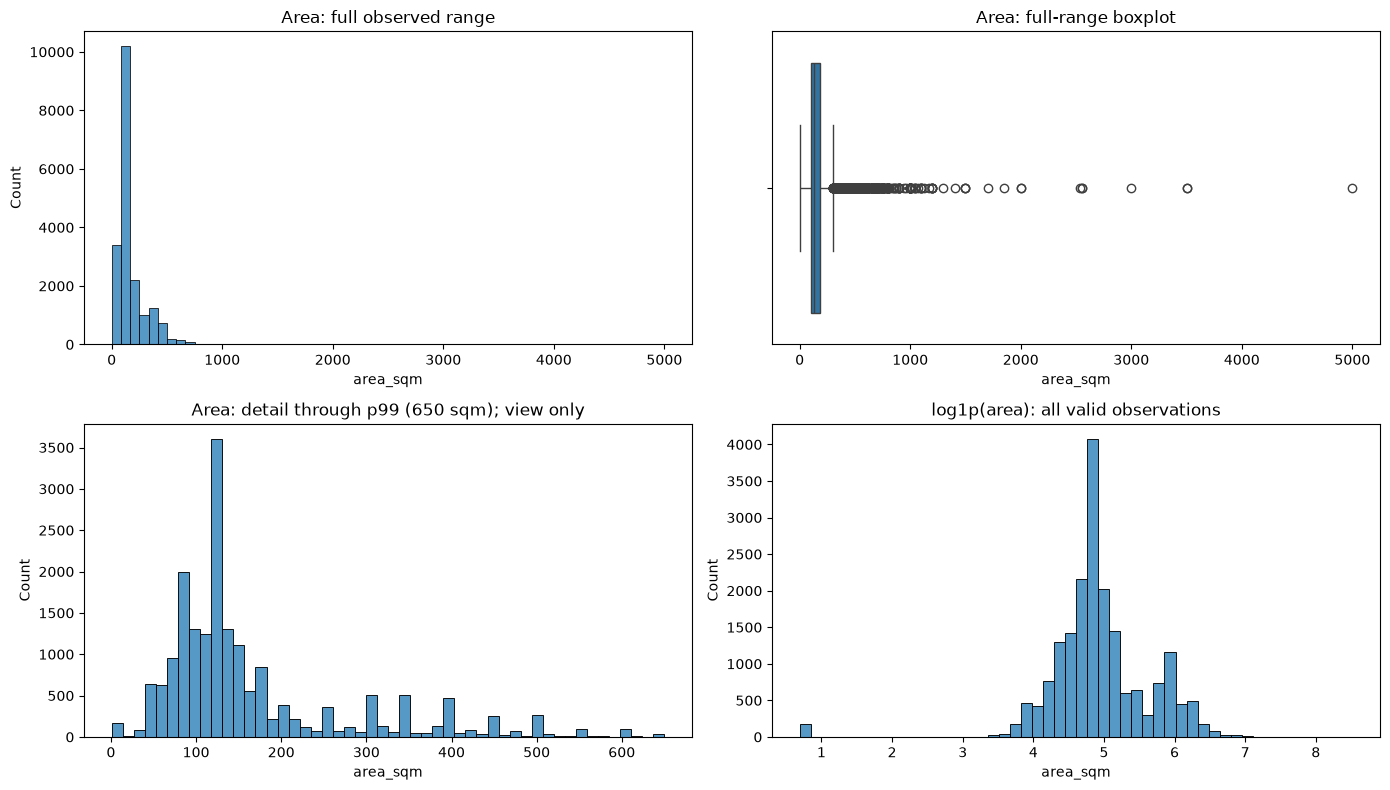

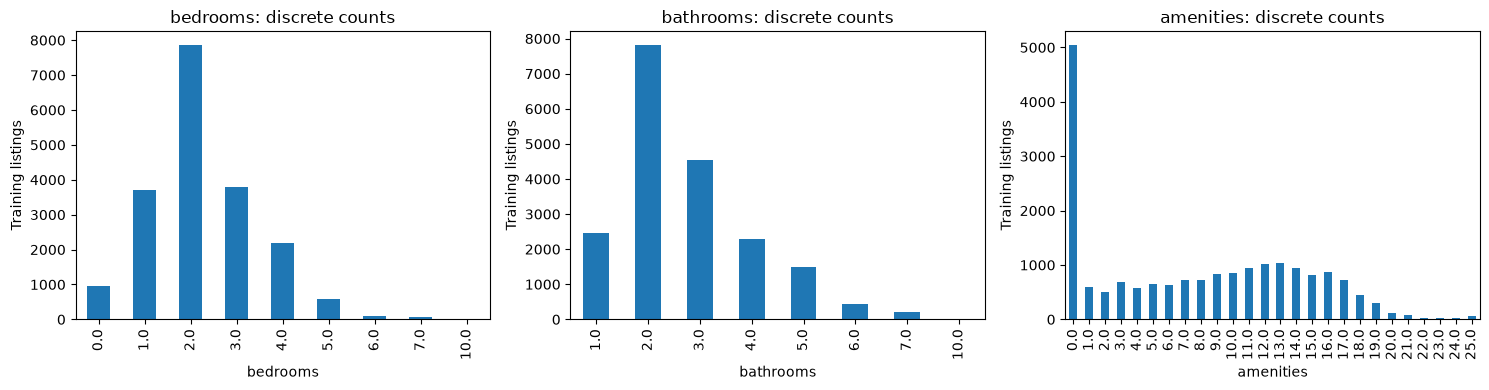

,maid,include_w_e
0.0,18069,10034
1.0,1185,9220


In [117]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
sns.histplot(area_valid.dropna(), bins=60, ax=axes[0, 0])
axes[0, 0].set_title('Area: full observed range')
sns.boxplot(x=area_valid.dropna(), ax=axes[0, 1])
axes[0, 1].set_title('Area: full-range boxplot')
p99 = area_valid.quantile(.99)
sns.histplot(area_valid[area_valid.le(p99)], bins=50, ax=axes[1, 0])
axes[1, 0].set_title(f'Area: detail through p99 ({p99:,.0f} sqm); view only')
sns.histplot(np.log1p(area_valid.dropna()), bins=50, ax=axes[1, 1])
axes[1, 1].set_title('log1p(area): all valid observations')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for col, ax in zip(count_cols, axes):
    finite_numeric[col].value_counts().sort_index().plot.bar(ax=ax)
    ax.set_title(f'{col}: discrete counts')
    ax.set_xlabel(col)
    ax.set_ylabel('Training listings')
plt.tight_layout()
plt.show()
display(pd.DataFrame({col: numeric_eda[col].value_counts(dropna=False) for col in binary_cols}).fillna(0).astype(int))

#### 3. Compare area transformations
Scaling changes units; it does **not** remove skewness or outliers. StandardScaler uses mean/standard deviation, whereas RobustScaler uses median/IQR and is less influenced by extremes when estimating scale. Compare raw area, both scalers, log1p, and fitted Yeo–Johnson on the same positive observations. Histograms and normal Q–Q plots show remaining tails; normal input features are not a requirement for regression. A lower absolute skewness alone does not prove better predictions.

,mean,median,std,skew,kurt,min,max
Raw,174.3061,130.0000,147.8386,6.0098,111.0907,1.0000,5000.0000
StandardScaler,0.0000,-0.2997,1.0000,6.0098,111.0907,-1.1723,32.6425
RobustScaler,0.5470,0.0000,1.8252,6.0098,111.0907,-1.5926,60.1235
log1p,4.9291,4.8752,0.7256,-1.3218,9.1605,0.6931,8.5174
Yeo-Johnson,0.0000,-0.1462,1.0000,0.1655,3.0987,-4.2441,7.3399


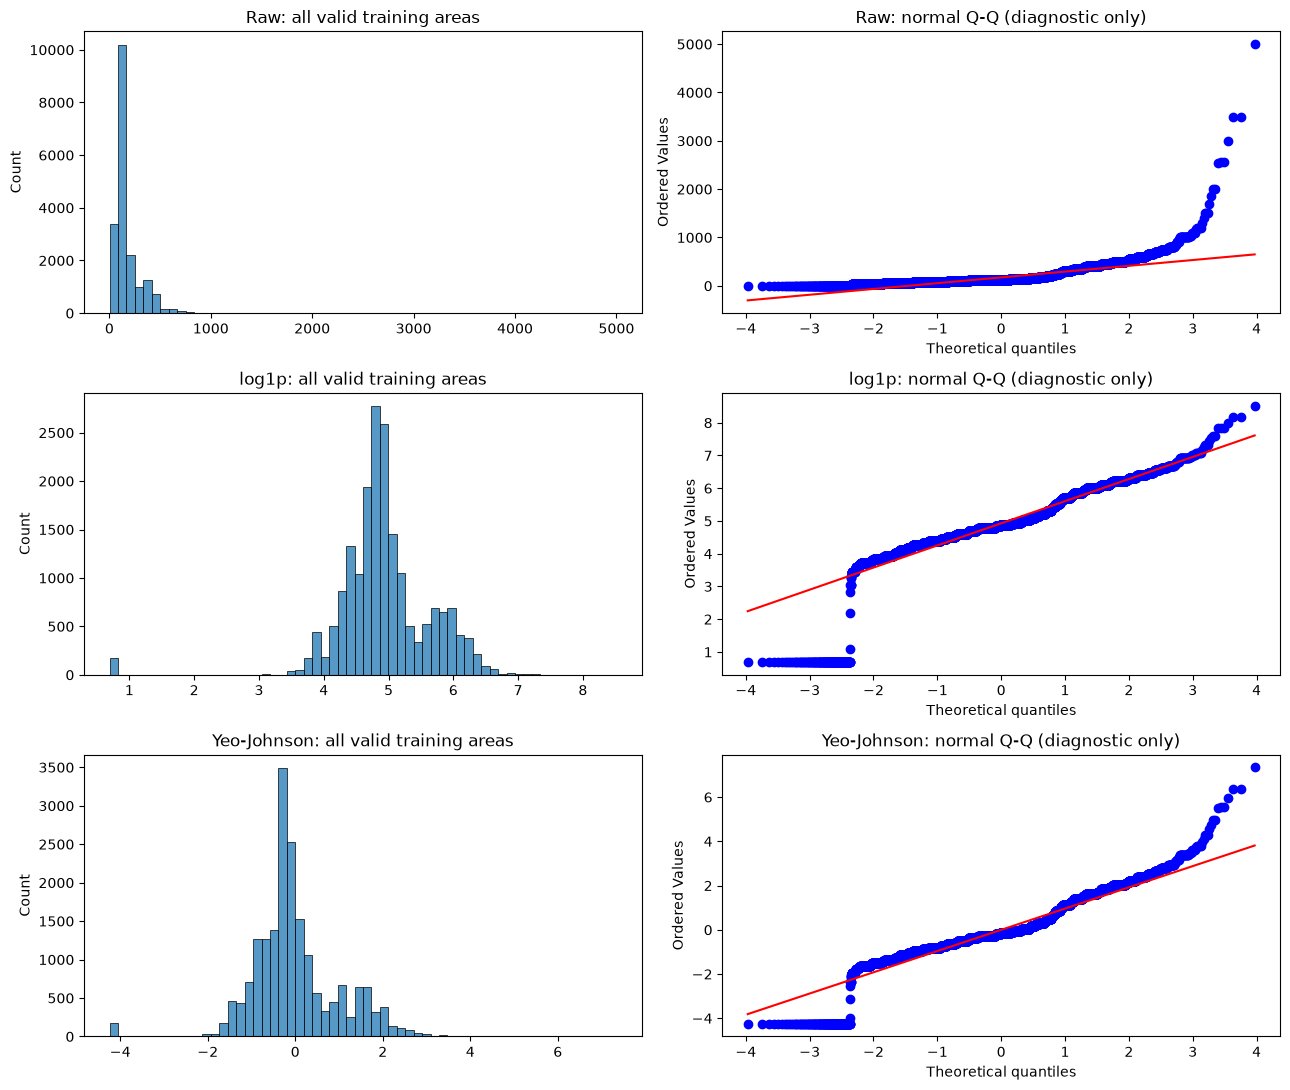

Absolute skewness, smallest first:


Yeo-Johnson       0.165500
log1p             1.321792
RobustScaler      6.009771
Raw               6.009771
StandardScaler    6.009771
Name: absolute_skewness, dtype: float64

In [118]:
area_observed = area_valid.dropna().to_numpy().reshape(-1, 1)
area_candidates = {
    'Raw': area_observed.ravel(),
    'StandardScaler': StandardScaler().fit_transform(area_observed).ravel(),
    'RobustScaler': RobustScaler().fit_transform(area_observed).ravel(),
    'log1p': np.log1p(area_observed).ravel(),
    'Yeo-Johnson': PowerTransformer(method='yeo-johnson').fit_transform(area_observed).ravel(),
}
area_comparison = pd.DataFrame(area_candidates).agg(['mean', 'median', 'std', 'skew', 'kurt', 'min', 'max']).T
display(area_comparison.round(4))
fig, axes = plt.subplots(3, 2, figsize=(13, 11))
for row, name in enumerate(['Raw', 'log1p', 'Yeo-Johnson']):
    values = area_candidates[name]
    sns.histplot(values, bins=60, ax=axes[row, 0])
    axes[row, 0].set_title(f'{name}: all valid training areas')
    stats.probplot(values, dist='norm', plot=axes[row, 1])
    axes[row, 1].set_title(f'{name}: normal Q-Q (diagnostic only)')
plt.tight_layout()
plt.show()
print('Absolute skewness, smallest first:')
display(area_comparison['skew'].abs().sort_values().rename('absolute_skewness'))

#### 4. Transformer recommendations

**Observed training results:** area has mean **173.70 sqm**, median **130 sqm**, and maximum **5,000 sqm**. The pooled IQR upper fence is **301.5 sqm**, flagging **3,595 rows (14.00%)**. No missing/nonpositive/nonfinite areas were found, but the minimum of **1 sqm** warrants source review. Bedrooms and bathrooms have 10 and 6 missing training values respectively.

Raw area skewness is **5.82** (excess kurtosis **107.89**). Both scalers preserve that skewness. `log1p` changes skewness to **−1.34** (kurtosis **9.21**), while **Yeo–Johnson** yields **0.17** (kurtosis **3.03**). Therefore, Yeo–Johnson is the leading distribution-transform candidate here; it is more symmetric, but still not normal. Compare its predictive MAE against simpler log1p and raw-area baselines before selecting the final model.

| Columns | Suggested starting point | Reason |
| --- | --- | --- |
| `area_sqm` | For linear/Ridge, SVR, or distance-based models: median imputation → **Yeo–Johnson (standardize=True)**; compare against **log1p + StandardScaler** and **raw + RobustScaler** in training cross-validation | The observed comparison favors Yeo–Johnson for reducing skew; its default standardization also puts area on a comparable scale. Robust scaling alone preserves skewness. The comparison above measures the actual change. |
| `bedrooms`, `bathrooms`, `amenities` | Most-frequent imputation for missing counts; **StandardScaler** for scale-sensitive models | Preserve count ordering and zeros; discrete features need not look Gaussian. No automatic log/power transformation or IQR clipping. |
| `maid`, `include_w_e` | **Pass through as 0/1** after validating their domain | Already binary, so no distribution transformation or scaling is needed. |
| All numeric features for tree models | Impute missing values if required by the estimator; begin with raw values | Trees generally do not need scaling. Compare alternatives using validation performance. |

Large area values remain review candidates, not confirmed mistakes. Correct only verified source/unit errors; do not delete rows solely because they cross the IQR fence. Nonpositive or nonfinite areas should be treated as missing for modeling. Quantile-to-normal mapping is not the default: it can obscure meaningful area distances and saturate unseen extremes. Box–Cox requires strictly positive inputs; log1p provides a simpler interpretable baseline.

Fit imputation, scaling, and power-transform parameters **inside each cross-validation training fold**. Choose the transformation using cross-validated rent MAE on the original rent scale, then evaluate once on `X_test`. The following unfitted numeric preprocessor is a suggested implementation for scale-sensitive models; combine it with the categorical preprocessing in a complete model pipeline.

In [119]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer

def positive_finite_area(values):
    values = np.asarray(values, dtype=float)
    return np.where(np.isfinite(values) & (values > 0), values, np.nan)

area_pipeline = Pipeline([
    ('valid_area', FunctionTransformer(positive_finite_area, feature_names_out='one-to-one')),
    ('impute', SimpleImputer(strategy='median')),
    ('power', PowerTransformer(method='yeo-johnson', standardize=True)),
])
count_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('scale', StandardScaler()),
])
numeric_preprocessor = ColumnTransformer([
    ('area', area_pipeline, ['area_sqm']),
    ('counts', count_pipeline, count_cols),
    ('binary', 'passthrough', binary_cols),
], remainder='drop')
# The next cell replaces the numerical columns with their transformed values.

In [120]:
# Run after the split/encoding cells, before fitting the model.
# Fit on training data only and replace the existing columns.
X_train['area_sqm'] = area_pipeline.fit_transform(X_train[['area_sqm']]).ravel()
X_val['area_sqm'] = area_pipeline.transform(X_val[['area_sqm']]).ravel()
X_test['area_sqm'] = area_pipeline.transform(X_test[['area_sqm']]).ravel()

# X_train[count_cols] = count_pipeline.fit_transform(X_train[count_cols])
# X_test[count_cols] = count_pipeline.transform(X_test[count_cols])

# maid and include_w_e remain binary.
X_train[['area_sqm'] + count_cols].head()


,area_sqm,bedrooms,bathrooms,amenities
11700,-0.040755,2,2,11
12923,-0.258279,2,2,20
30778,-0.661543,1,2,0
7795,-0.146155,2,2,4
29514,0.009692,3,3,0


In [121]:
from sklearn.impute import SimpleImputer

# Columns with missing values
cols = ['bedrooms', 'bathrooms']

# Initialize imputer
imputer = SimpleImputer(strategy='median')

# Fit and transform training data
X_train[cols] = imputer.fit_transform(X_train[cols])

# Transform testing data (without fitting)
X_val[cols] = imputer.transform(X_val[cols])

X_test[cols] = imputer.transform(X_test[cols])

# Verify
print(X_train[cols].isnull().sum())
print(X_val[cols].isnull().sum())
print(X_test[cols].isnull().sum())

bedrooms     0
bathrooms    0
dtype: int64
bedrooms     0
bathrooms    0
dtype: int64
bedrooms     0
bathrooms    0
dtype: int64


In [130]:
X_train.head()

,bedrooms,maid,bathrooms,area_sqm,include_w_e,amenities,furnished,property_type_Bulk Rent Unit,property_type_Hotel Apartment,property_type_Land,...,area_group_Durrat & Zallaq,area_group_Juffair,area_group_Manama Residential,area_group_Muharraq & Hidd,area_group_Reef Island,area_group_Riffa,area_group_Saar & Janabiya,area_group_Seef & Bahrain Bay,area_group_Tubli & Sanad & Jid Ali,area_group_nan
11700,2.0,0,2.0,-0.040755,1,11,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
12923,2.0,0,2.0,-0.258279,1,20,2.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30778,1.0,0,2.0,-0.661543,0,0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
7795,2.0,0,2.0,-0.146155,0,4,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
29514,3.0,0,3.0,0.009692,0,0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


## DL Model

In [131]:
y_train

11700    330.0
12923    650.0
30778    450.0
7795     300.0
29514    310.0
         ...  
28037    450.0
27650    340.0
4990     775.0
25667    480.0
29629    170.0
Name: rent, Length: 19254, dtype: float64

In [136]:
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping
from keras.models import Sequential
from keras.layers import Dense, Input

#Step 1

model = Sequential()

model.add(Input(shape=(X_train.shape[1],)))  #input layer with 1 feature
model.add(Dense(32, activation = "relu"))  # hidden layer with 3 neurons (nodes)
model.add(Dense(8, activation = "relu"))  # hidden layer with 20 neurons
#model.add(Dense(15, activation = "relu"))  # hidden layer with 15 neurons
model.add(Dense(1, activation = "linear"))  # output layer

#Step 2: Instantiate a custom optimizer

optimizer = Adam(learning_rate=0.001)  # Default Adam LR = 0.001

model.compile(
            loss='mae', 
            optimizer=optimizer)

#Step 3: Fitting with early stopping

es=EarlyStopping(monitor='val_loss', 
                 patience=5,
                 restore_best_weights=True)

history = model.fit(
                    X_train,
                    y_train, 
                    validation_data=(X_val,y_val),
                    epochs=100,
                    batch_size=64,
                    callbacks=[es])

Epoch 1/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 591.3878 - val_loss: 466.6708
Epoch 2/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 318.0292 - val_loss: 379.8396
Epoch 3/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 268.1156 - val_loss: 356.7841
Epoch 4/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 257.0950 - val_loss: 350.6510
Epoch 5/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 251.9987 - val_loss: 346.1506
Epoch 6/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 248.5953 - val_loss: 343.3808
Epoch 7/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 246.3137 - val_loss: 341.4271
Epoch 8/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 244.6016 - val_loss: 340.0002
Epoch 9/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 243.2411 - val_loss: 339.0389
Epoch 10/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 242.1618 - val_loss: 337.5661
Epoch 11/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 241.1797 - val_loss: 336.68

Text(0, 0.5, 'loss')

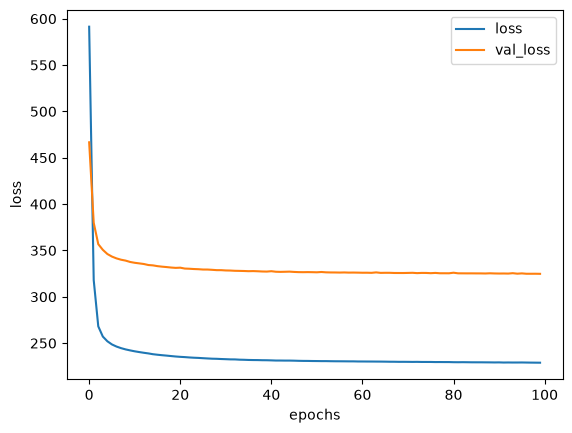

In [137]:
# Plot loss vs val_loss

history_df = pd.DataFrame(history.history)

history_df.plot()
plt.xlabel("epochs")
plt.ylabel("loss")
#plt.yscale('log')
